# 04 · Ajuste, Calibración, Evaluación Final y Exportación — Customer Churn

En este último cuaderno completamos el ciclo de vida del modelo de Machine Learning:
1. Tomamos los **3 mejores candidatos** seleccionados en el notebook 03.
2. Optimizamos sus hiperparámetros mediante búsqueda en grilla (`GridSearchCV`) con validación cruzada estratificada sobre el conjunto de entrenamiento.
3. Calibramos las probabilidades predichas mediante escalado sigmoide (Platt scaling) para producir probabilidades calibradas, sin garantizar que equivalgan al riesgo real fuera de estos datos.
4. Determinamos el **umbral óptimo de decisión** que maximiza el $F_1	ext{-score}$ en validación cruzada.
5. Seleccionamos el modelo ganador y lo entrenamos con **todo el conjunto de entrenamiento**.
6. Evaluamos el modelo final **una sola vez** sobre el conjunto de prueba independiente (`test.csv`).
7. Exportamos el modelo final y sus metadatos a `models/modelo_final.joblib` y `models/metadata_modelo.json` para ser consumidos por la aplicación interactiva (`app.py`).


## 1. Configuración de rutas

Definimos las rutas del proyecto y la variable `EN_COLAB` para permitir su ejecución local o en Google Colab.


In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install imbalanced-learn -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"


## 2. Importaciones

Importamos las librerías necesarias de scikit-learn e imbalanced-learn para optimización de hiperparámetros, calibración, métricas y persistencia del modelo.


In [2]:
import os
import json
import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, precision_recall_curve
)

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)


## 3. Cargar datos de entrenamiento y decisiones anteriores

Cargamos el conjunto de entrenamiento `train.csv`, las decisiones de preprocesamiento del notebook 02 (`decisiones_preprocesamiento.joblib`) y los 3 mejores candidatos seleccionados en el notebook 03 (`03_candidatos.csv`).


In [3]:
train = pd.read_csv(RUTA_DATOS + "train.csv")
candidatos = pd.read_csv(RUTA_RESULTADOS + "03_candidatos.csv")
decisiones = joblib.load(RUTA_MODELOS + "decisiones_preprocesamiento.joblib")

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
columnas_entrada = list(X_train.columns)
plantilla = decisiones["preprocesamiento"]

print("Filas de entrenamiento:", len(train))
print("Variables predictoras:", len(columnas_entrada))
print("\nLos 3 mejores candidatos del notebook 03:")
display(candidatos[["Modelo", "Estrategia", "F1", "Recall", "Precision", "ROC_AUC"]])


Filas de entrenamiento: 2520
Variables predictoras: 11

Los 3 mejores candidatos del notebook 03:


,Modelo,Estrategia,F1,Recall,Precision,ROC_AUC
0,Random Forest,class_weight,0.851932,0.871218,0.834703,0.978573
1,Stacking,SMOTENC,0.816727,0.856026,0.783006,0.971039
2,Bagging,SMOTENC,0.808662,0.853397,0.769335,0.959345


## 4. Funciones auxiliares de modelado y calibración

Reutilizamos las funciones para ensamblar pipelines y construir las funciones que permiten obtener puntajes continuos, calibrar probabilidades y buscar el umbral óptimo de decisión.

**Orden del pipeline:** escalador → balanceador (si aplica) → ANOVA → clasificador. El escalador conserva las once columnas y su orden; SMOTENC recibe `quejas` y `plan_tarifario` en sus posiciones originales, antes de que ANOVA seleccione variables. Con remuestreo, ANOVA se ajusta sobre los datos balanceados de cada pliegue; en el notebook 02 se evaluó sin remuestreo. Esto puede cambiar las variables seleccionadas y los resultados. Todas estas operaciones se ajustan únicamente con el entrenamiento de cada pliegue.


In [4]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
particiones_cv = list(cv.split(X_train, y_train))

COLUMNAS_CATEGORICAS = ["quejas", "plan_tarifario"]
posiciones_cat = []
for i in range(len(columnas_entrada)):
    col = columnas_entrada[i]
    if col in COLUMNAS_CATEGORICAS:
        posiciones_cat.append(i)


def crear_balanceador(estrategia, posiciones_categoricas):
    """Devuelve el remuestreador correspondiente según la estrategia seleccionada."""
    if estrategia == "Sin balanceo" or estrategia == "class_weight":
        return None
    elif estrategia == "SMOTENC":
        return SMOTENC(categorical_features=posiciones_categoricas, random_state=42)
    elif estrategia == "Submuestreo":
        return RandomUnderSampler(random_state=42)
    else:
        raise ValueError(f"Estrategia no reconocida: {estrategia}")


def armar_pipeline(plantilla, modelo, estrategia, posiciones_categoricas):
    """Construye el pipeline en orden escalador, balanceador, transformador y modelo."""
    preparacion = clone(plantilla)
    pasos = [("escalador", preparacion.named_steps["escalador"])]
    balanceador = crear_balanceador(estrategia, posiciones_categoricas)
    if balanceador is not None:
        pasos.append(("balanceo", balanceador))

    pasos.append(("transformador", preparacion.named_steps["transformador"]))
    modelo_clonado = clone(modelo)
    if estrategia == "class_weight":
        modelo_clonado.set_params(class_weight="balanced")

    pasos.append(("modelo", modelo_clonado))
    return Pipeline(pasos)


def buscar_modelo(nombre):
    """Instancia el estimador correspondiente al nombre recibido."""
    if nombre == "Random Forest":
        return RandomForestClassifier(n_estimators=200, random_state=42)
    elif nombre == "Stacking":
        return StackingClassifier(
            estimators=[
                ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                ("svm", SVC(random_state=42)),
                ("knn", KNeighborsClassifier(n_neighbors=5))
            ],
            final_estimator=LogisticRegression(max_iter=2000),
            cv=5
        )
    elif nombre == "Bagging":
        return BaggingClassifier(random_state=42)
    elif nombre == "Red neuronal (MLP)":
        return MLPClassifier(max_iter=1000, random_state=42)
    else:
        raise ValueError(f"Modelo no reconocido: {nombre}")


def obtener_puntaje(pipeline, X):
    """
    Devuelve un puntaje continuo para cada fila: la función de decisión si existe,
    o el logit de la probabilidad estimada (clip a [1e-6, 1 - 1e-6]).
    """
    if hasattr(pipeline, "decision_function"):
        return np.asarray(pipeline.decision_function(X)).ravel()
    prob = np.clip(pipeline.predict_proba(X)[:, 1], 1e-6, 1.0 - 1e-6)
    return np.log(prob / (1.0 - prob))


def predecir_probabilidad(resultado_candidato, X):
    """Genera probabilidades calibradas pasando el puntaje del pipeline por el calibrador sigmoide."""
    puntajes = obtener_puntaje(resultado_candidato["pipeline"], X)
    return resultado_candidato["calibrador"].predict_proba(puntajes.reshape(-1, 1))[:, 1]


def calcular_metricas(y_real, y_pred, probabilidades):
    """Calcula el conjunto completo de métricas de clasificación y calibración."""
    return {
        "F1": f1_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_real, probabilidades),
        "Precision_promedio": average_precision_score(y_real, probabilidades),
        "Accuracy": accuracy_score(y_real, y_pred),
        "Brier": brier_score_loss(y_real, probabilidades)
    }


## 5. Grillas de hiperparámetros

Definimos las grillas de búsqueda para los 3 mejores modelos candidatos. Mantenemos grillas enfocadas para garantizar precisión y tiempos razonables de cómputo.


In [5]:
def obtener_grilla(nombre_modelo, estrategia):
    """Devuelve el espacio de búsqueda para GridSearchCV."""
    grillas = {
        "Random Forest": {
            "modelo__n_estimators": [200, 300],
            "modelo__max_depth": [10, 15, None],
            "modelo__min_samples_leaf": [1, 2]
        },
        "Stacking": {
            "modelo__final_estimator__C": [0.1, 1.0, 10.0]
        },
        "Bagging": {
            "modelo__n_estimators": [10, 50],
            "modelo__max_samples": [0.7, 1.0]
        },
        "Red neuronal (MLP)": {
            "modelo__hidden_layer_sizes": [(100,), (100, 50)],
            "modelo__alpha": [0.0001, 0.001]
        }
    }
    grilla = grillas[nombre_modelo].copy()
    if estrategia == "SMOTENC":
        grilla["balanceo__k_neighbors"] = [3, 5]
    return grilla

for i in range(len(candidatos)):
    mod = candidatos.loc[i, "Modelo"]
    est = candidatos.loc[i, "Estrategia"]
    print(f"{mod} ({est}) -> {obtener_grilla(mod, est)}")


Random Forest (class_weight) -> {'modelo__n_estimators': [200, 300], 'modelo__max_depth': [10, 15, None], 'modelo__min_samples_leaf': [1, 2]}
Stacking (SMOTENC) -> {'modelo__final_estimator__C': [0.1, 1.0, 10.0], 'balanceo__k_neighbors': [3, 5]}
Bagging (SMOTENC) -> {'modelo__n_estimators': [10, 50], 'modelo__max_samples': [0.7, 1.0], 'balanceo__k_neighbors': [3, 5]}


## 6. Procedimiento de ajuste, calibración y selección de umbral

Para cada candidato:
1. Usamos `GridSearchCV` con `scoring="average_precision"` sobre las particiones de validación cruzada para encontrar los mejores hiperparámetros.
2. Obtenemos las predicciones fuera de pliegue (*out-of-fold*) para ajustar una regresión logística sigmoide (calibrador de Platt).
3. Buscamos el umbral de decisión entre 0,05 y 0,95 (en pasos de 0,01) que maximiza el $F_1	ext{-score}$ sobre los datos de entrenamiento.
4. Reentrenamos el pipeline completo con los mejores parámetros y conservamos el calibrador OOF con el que se eligió el umbral.


In [6]:
def ajustar_candidato(pipeline_base, grilla, X, y, particiones):
    """
    Ajusta hiperparámetros con GridSearchCV, calibra con predicciones fuera de pliegue
    y encuentra el umbral óptimo de decisión.
    """
    # 1. Búsqueda de hiperparámetros
    grid = GridSearchCV(
        pipeline_base,
        param_grid=grilla,
        cv=particiones,
        scoring="average_precision",
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )
    grid.fit(X, y)
    mejor_pipeline = grid.best_estimator_

    # 2. Generación de puntajes fuera de pliegue para calibración
    puntajes_oof = np.zeros(len(y))
    for indices_tr, indices_val in particiones:
        pipe_pliegue = clone(mejor_pipeline)
        pipe_pliegue.fit(X.iloc[indices_tr], y.iloc[indices_tr])
        puntajes_oof[indices_val] = obtener_puntaje(pipe_pliegue, X.iloc[indices_val])

    # 3. Ajuste del calibrador sigmoide
    calibrador = LogisticRegression(solver="lbfgs", max_iter=2000)
    calibrador.fit(puntajes_oof.reshape(-1, 1), y)
    probabilidades_cv = calibrador.predict_proba(puntajes_oof.reshape(-1, 1))[:, 1]

    # 4. Búsqueda de umbral óptimo de F1
    umbrales = np.arange(0.05, 0.95, 0.01)
    filas_umbral = []
    mejor_f1 = -1.0
    mejor_umbral = 0.50

    for u in umbrales:
        pred_u = (probabilidades_cv >= u).astype(int)
        f1_u = f1_score(y, pred_u, zero_division=0)
        rec_u = recall_score(y, pred_u, zero_division=0)
        prec_u = precision_score(y, pred_u, zero_division=0)
        filas_umbral.append({"Umbral": u, "F1": f1_u, "Recall": rec_u, "Precision": prec_u})
        if f1_u > mejor_f1:
            mejor_f1 = f1_u
            mejor_umbral = u

    # 5. Ajuste final con todo el conjunto de entrenamiento
    mejor_pipeline.fit(X, y)
    # Conservamos el calibrador OOF con el que se seleccionó el umbral.
    # Reajustarlo con puntajes de entrenamiento cambiaría la escala de probabilidades.

    return {
        "pipeline": mejor_pipeline,
        "calibrador": calibrador,
        "parametros": grid.best_params_,
        "umbral": round(float(mejor_umbral), 2),
        "probabilidades_cv": probabilidades_cv,
        "tabla_umbrales": pd.DataFrame(filas_umbral)
    }


## 7. Ejecución del ajuste sobre los tres mejores modelos

Ejecutamos el procedimiento completo sobre los 3 candidatos y comparamos su desempeño en validación cruzada con probabilidades calibradas.


El F1 ajustado es una métrica de selección sobre train. La media y desviación del modelo previo al ajuste se reportan por separado; no se combinan como un F1 ajustado ± desviación. No hay validación anidada.

In [7]:
rows_ajuste = []
resultados_finales = {}

for i in range(len(candidatos)):
    nombre_m = candidatos.loc[i, "Modelo"]
    estrategia_m = candidatos.loc[i, "Estrategia"]
    print(f"\nAjustando: {nombre_m} ({estrategia_m})...")

    pipeline_cand = armar_pipeline(plantilla, buscar_modelo(nombre_m), estrategia_m, posiciones_cat)
    grilla_cand = obtener_grilla(nombre_m, estrategia_m)

    resultado = ajustar_candidato(pipeline_cand, grilla_cand, X_train, y_train, particiones_cv)
    resultados_finales[nombre_m] = resultado

    pred_cv = (resultado["probabilidades_cv"] >= resultado["umbral"]).astype(int)
    met_cv = calcular_metricas(y_train, pred_cv, resultado["probabilidades_cv"])

    rows_ajuste.append({
        "Modelo": nombre_m,
        "Estrategia": estrategia_m,
        "F1_03": candidatos.loc[i, "F1"],
        "F1_03_Std": float(candidatos.loc[i, "F1_std"]),
        "F1_Seleccion_Ajustado": met_cv["F1"],
        "Umbral": resultado["umbral"],
        "Recall": met_cv["Recall"],
        "Precision": met_cv["Precision"],
        "ROC_AUC": met_cv["ROC_AUC"],
        "Brier": met_cv["Brier"],
        "Mejores_parametros": str(resultado["parametros"])
    })
    print(f"Mejores parámetros: {resultado['parametros']}")
    print(f"Umbral óptimo: {resultado['umbral']} -> F1 selección: {met_cv['F1']:.3f} | Recall: {met_cv['Recall']:.3f} | Precisión: {met_cv['Precision']:.3f}")

tabla_ajuste = pd.DataFrame(rows_ajuste).sort_values("F1_Seleccion_Ajustado", ascending=False).reset_index(drop=True)
tabla_ajuste.to_csv(RUTA_RESULTADOS + "ajuste_hiperparametros.csv", index=False)
display(tabla_ajuste.round(3))



Ajustando: Random Forest (class_weight)...


Mejores parámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
Umbral óptimo: 0.29 -> F1 selección: 0.859 | Recall: 0.922 | Precisión: 0.804

Ajustando: Stacking (SMOTENC)...


Mejores parámetros: {'balanceo__k_neighbors': 3, 'modelo__final_estimator__C': 10.0}
Umbral óptimo: 0.22 -> F1 selección: 0.832 | Recall: 0.904 | Precisión: 0.770

Ajustando: Bagging (SMOTENC)...


Mejores parámetros: {'balanceo__k_neighbors': 5, 'modelo__max_samples': 0.7, 'modelo__n_estimators': 50}
Umbral óptimo: 0.27 -> F1 selección: 0.817 | Recall: 0.869 | Precisión: 0.771


,Modelo,Estrategia,F1_03,F1_03_Std,F1_Seleccion_Ajustado,Umbral,Recall,Precision,ROC_AUC,Brier,Mejores_parametros
0,Random Forest,class_weight,0.852,0.048,0.859,0.29,0.922,0.804,0.980,0.040,"{'modelo__max_depth': 15, 'modelo__min_samples..."
1,Stacking,SMOTENC,0.817,0.043,0.832,0.22,0.904,0.770,0.971,0.044,"{'balanceo__k_neighbors': 3, 'modelo__final_es..."
2,Bagging,SMOTENC,0.809,0.050,0.817,0.27,0.869,0.771,0.969,0.050,"{'balanceo__k_neighbors': 5, 'modelo__max_samp..."


## 8. Selección del modelo final y análisis de umbral

Elegimos como modelo definitivo el clasificador con mayor $F_1$ en validación cruzada. Analizamos su curva de métricas ($F_1$, Recall y Precisión) según el umbral de decisión.


Modelo seleccionado como FINAL: Random Forest (class_weight)
Umbral de alerta asignado: 0.29


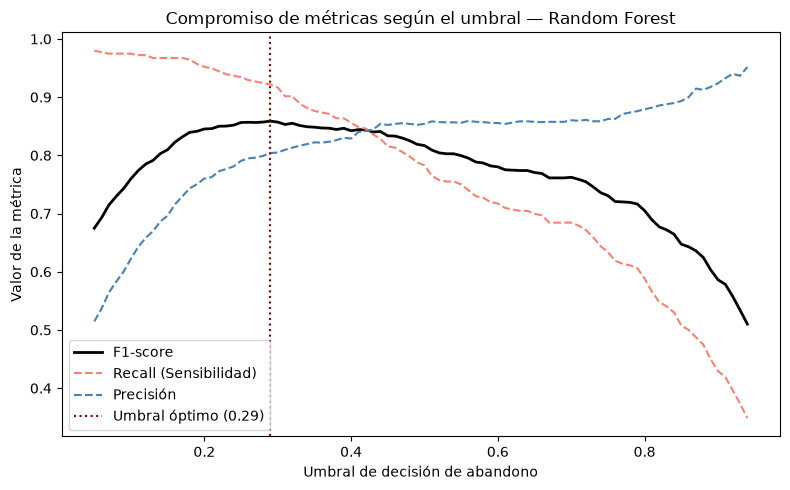

In [8]:
nombre_final = tabla_ajuste.loc[0, "Modelo"]
estrategia_final = tabla_ajuste.loc[0, "Estrategia"]
resultado_final = resultados_finales[nombre_final]
umbral_final = resultado_final["umbral"]

print(f"Modelo seleccionado como FINAL: {nombre_final} ({estrategia_final})")
print(f"Umbral de alerta asignado: {umbral_final}")

# Gráfico de F1, Recall y Precisión en función del umbral
tabla_u = resultado_final["tabla_umbrales"]
plt.figure(figsize=(8, 5))
plt.plot(tabla_u["Umbral"], tabla_u["F1"], label="F1-score", color="black", lw=2)
plt.plot(tabla_u["Umbral"], tabla_u["Recall"], label="Recall (Sensibilidad)", color="salmon", ls="--")
plt.plot(tabla_u["Umbral"], tabla_u["Precision"], label="Precisión", color="steelblue", ls="--")
plt.axvline(umbral_final, color="darkred", ls=":", label=f"Umbral óptimo ({umbral_final})")
plt.title(f"Compromiso de métricas según el umbral — {nombre_final}")
plt.xlabel("Umbral de decisión de abandono")
plt.ylabel("Valor de la métrica")
plt.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "04_f1_recall_precision_vs_umbral.png", dpi=150)
plt.show()


## 9. Evaluación final en el conjunto de prueba (`test.csv`)

Cargamos el conjunto de prueba independiente `test.csv` (630 registros, 99 casos reales de abandono).
Evaluamos el modelo final con el umbral seleccionado en entrenamiento. Este conjunto ya se consultó para diagnosticar el error de calibración: la reevaluación verifica la corrección, pero no constituye una validación nueva intacta.


In [9]:
test = pd.read_csv(RUTA_DATOS + "test.csv")
X_test = test[columnas_entrada]
y_test = test["abandono"]

probabilidades_test = predecir_probabilidad(resultado_final, X_test)
y_pred_test = (probabilidades_test >= umbral_final).astype(int)

print(f"Registros de prueba: {len(test)} | Casos de abandono reales: {int(y_test.sum())} ({y_test.mean()*100:.2f}%)")
print("\nReporte de Clasificación en Conjunto de Prueba:")
print(classification_report(y_test, y_pred_test, target_names=["Permanece", "Abandona"], digits=3))

metricas_test = calcular_metricas(y_test, y_pred_test, probabilidades_test)
print("\nMétricas consolidadas en test:")
for k, v in metricas_test.items():
    print(f" - {k:<20}: {v:.4f}")


Registros de prueba: 630 | Casos de abandono reales: 99 (15.71%)

Reporte de Clasificación en Conjunto de Prueba:
              precision    recall  f1-score   support

   Permanece      0.990     0.968     0.979       531
    Abandona      0.847     0.949     0.895        99

    accuracy                          0.965       630
   macro avg      0.919     0.959     0.937       630
weighted avg      0.968     0.965     0.966       630


Métricas consolidadas en test:
 - F1                  : 0.8952
 - Recall              : 0.9495
 - Precision           : 0.8468
 - ROC_AUC             : 0.9872
 - Precision_promedio  : 0.9191
 - Accuracy            : 0.9651
 - Brier               : 0.0325


Visualizamos la matriz de confusión y las curvas ROC y Precisión-Recall en el conjunto de prueba.


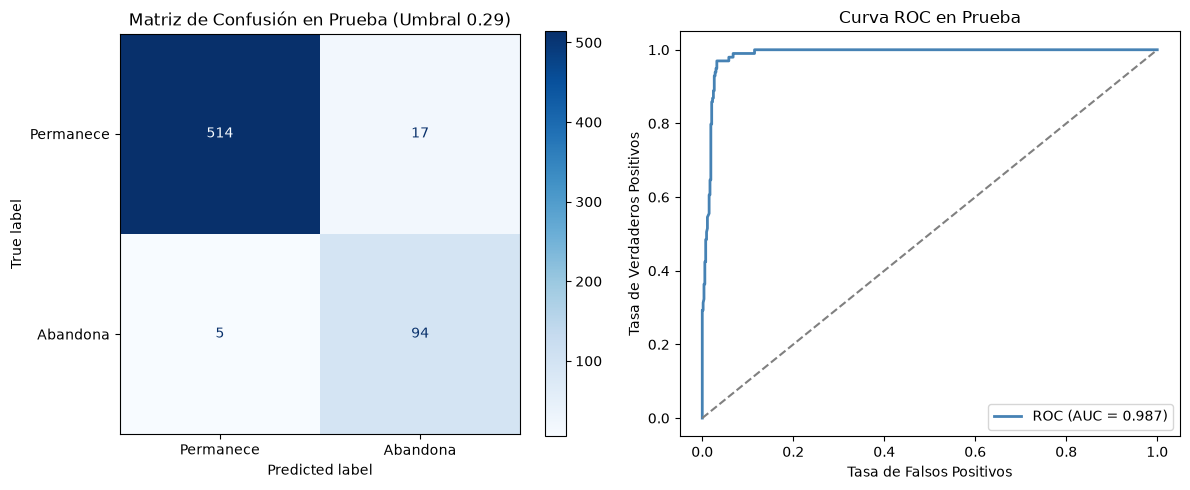

Abandonos detectados correctamente (True Positives): 94 de 99 (94.9%)
Falsas alarmas (False Positives): 17 entre 531 clientes que permanecen (3.2%)


In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=["Permanece", "Abandona"],
    cmap="Blues",
    values_format="d",
    ax=ejes[0]
)
ejes[0].set_title(f"Matriz de Confusión en Prueba (Umbral {umbral_final})")

# 2. Curvas ROC y Precision-Recall
fpr, tpr, _ = roc_curve(y_test, probabilidades_test)
prec_c, rec_c, _ = precision_recall_curve(y_test, probabilidades_test)

ejes[1].plot(fpr, tpr, color="steelblue", lw=2, label=f"ROC (AUC = {metricas_test['ROC_AUC']:.3f})")
ejes[1].plot([0, 1], [0, 1], color="gray", ls="--")
ejes[1].set_xlabel("Tasa de Falsos Positivos")
ejes[1].set_ylabel("Tasa de Verdaderos Positivos")
ejes[1].set_title("Curva ROC en Prueba")
ejes[1].legend()

plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "04_matriz_confusion_test.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f"Abandonos detectados correctamente (True Positives): {tp} de {tp + fn} ({tp/(tp+fn)*100:.1f}%)")
print(f"Falsas alarmas (False Positives): {fp} entre {tn + fp} clientes que permanecen ({fp/(tn+fp)*100:.1f}%)")


## 10. Exportación del modelo final y metadatos

Guardamos el artefacto del modelo (`models/modelo_final.joblib`) y el archivo de configuración `metadata_modelo.json`.
La estructura exportada es exactamente la requerida por la aplicación interactiva (`app.py`), permitiendo evaluar clientes individuales y priorizar archivos CSV.


In [11]:
artefacto = {
    "pipeline": resultado_final["pipeline"],
    "calibrador": resultado_final["calibrador"],
    "umbral": float(umbral_final),
    "columnas_entrada": columnas_entrada,
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final
}
joblib.dump(artefacto, RUTA_MODELOS + "modelo_final.joblib")

hiperparametros_dict = {}
for k, v in resultado_final["parametros"].items():
    hiperparametros_dict[k] = str(v)

metricas_test_dict = {}
for k, v in metricas_test.items():
    metricas_test_dict[k] = float(v)

metricas_seleccion_dict = {
    "F1": float(tabla_ajuste.loc[0, "F1_Seleccion_Ajustado"]),
    "Recall": float(tabla_ajuste.loc[0, "Recall"]),
    "Precision": float(tabla_ajuste.loc[0, "Precision"]),
    "ROC_AUC": float(tabla_ajuste.loc[0, "ROC_AUC"]),
    "Brier": float(tabla_ajuste.loc[0, "Brier"])
}

metadata = {
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final,
    "preprocesamiento": decisiones["alternativa"],
    "calibracion": "sigmoide (Platt scaling)",
    "columnas_entrada": columnas_entrada,
    "umbral": float(umbral_final),
    "hiperparametros": hiperparametros_dict,
    "metricas_seleccion_entrenamiento": metricas_seleccion_dict,
    "metricas_comparacion_previa": {
        "F1_media": float(tabla_ajuste.loc[0, "F1_03"]),
        "F1_desviacion": float(tabla_ajuste.loc[0, "F1_03_Std"]),
        "procedimiento": "Modelo previo al ajuste: CV estratificada de diez particiones, sin grupos"
    },
    "procedimiento_seleccion": "Ajuste de hiperparámetros, calibración OOF y selección de umbral sobre train; sin validación anidada",
    "procedimiento_calibracion": "Sigmoide ajustada con puntajes fuera de pliegue y conservada para inferencia con el umbral elegido",
    "contexto_test": "Conjunto reservado que ya se consultó para diagnosticar la calibración; la reevaluación no es una validación nueva intacta",
    "metricas_test": metricas_test_dict,
    "intervalos_bootstrap_test_95": {},
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_sklearn": sklearn.__version__,
    "version_imblearn": imblearn.__version__
}

with open(RUTA_MODELOS + "metadata_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Artefactos exportados exitosamente:")
print(" -", RUTA_MODELOS + "modelo_final.joblib")
print(" -", RUTA_MODELOS + "metadata_modelo.json")


Artefactos exportados exitosamente:
 - ./models/modelo_final.joblib
 - ./models/metadata_modelo.json


## 11. Verificación de recarga del modelo

Verificamos que el archivo `modelo_final.joblib` guardado en disco se pueda cargar y genere exactamente las mismas probabilidades y predicciones que el modelo original en memoria.


In [12]:
artefacto_cargado = joblib.load(RUTA_MODELOS + "modelo_final.joblib")

puntajes_recargados = obtener_puntaje(artefacto_cargado["pipeline"], X_test)
prob_recargadas = artefacto_cargado["calibrador"].predict_proba(puntajes_recargados.reshape(-1, 1))[:, 1]
pred_recargadas = (prob_recargadas >= artefacto_cargado["umbral"]).astype(int)

diferencia_maxima = np.max(np.abs(probabilidades_test - prob_recargadas))
coincidencia_exacta = np.array_equal(y_pred_test, pred_recargadas)

print(f"Diferencia numérica máxima entre predicciones: {diferencia_maxima:.2e}")
print(f"¿Predicciones discretas idénticas al 100%?: {coincidencia_exacta}")


Diferencia numérica máxima entre predicciones: 0.00e+00
¿Predicciones discretas idénticas al 100%?: True


## 12. Conclusiones

Resumimos el modelo y el umbral elegidos con entrenamiento, junto con las métricas de prueba calculadas en esta ejecución. El ajuste mantiene el orden escalador → balanceador (si aplica) → ANOVA → clasificador. El calibrador OOF y el umbral se conservan juntos. Las métricas de selección no son validación anidada; el mismo entrenamiento interviene en elegir hiperparámetros, calibración y umbral. Los artefactos exportados corresponden a la ejecución actual y se comprueba su recarga.


In [13]:
resumen_final = pd.DataFrame([{
    "Modelo": nombre_final,
    "Estrategia": estrategia_final,
    "Umbral": umbral_final,
    "F1_test": metricas_test["F1"],
    "Recall_test": metricas_test["Recall"],
    "Precision_test": metricas_test["Precision"],
    "ROC_AUC_test": metricas_test["ROC_AUC"],
    "Abandonos_detectados": int(tp),
    "Abandonos_reales": int(tp + fn)
}])
display(resumen_final.round(4))


,Modelo,Estrategia,Umbral,F1_test,Recall_test,Precision_test,ROC_AUC_test,Abandonos_detectados,Abandonos_reales
0,Random Forest,class_weight,0.29,0.8952,0.9495,0.8468,0.9872,94,99
